In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import mixedlm, ols
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline

In [2]:
basedir = pathlib.Path("/media/mplitt/SSD_storage/2P_scratch/Dh31Gal4_OctAlpha2R_RNAi_R27F02LexA_jGCaMP7b")

sess_df = pd.read_csv(basedir / 'sessions.csv')
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['condition'] for _, row in sess_df.iterrows()]

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_jGCaMP7b_TBHRNAi/')
figfolder.mkdir(parents=True, exist_ok=True)

sess_df = sess_df.loc[sess_df['usable']==1]



Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'fictrac_file', 'condition',
       'scan_type', 'closed_loop', 'dark', 'usable', 'notes'],
      dtype='str')


In [3]:
sess_df.iloc[-2:]

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,closed_loop,dark,usable,notes,fly_id
124,13_07_2026,fly6,closed_loop-000,0,fictrac-20260713_141806.dat,rnai_only,closed_loop,1,0,1,NaN,13_07_2026_fly6_rnai_only
125,13_07_2026,fly6,dark-001,1,fictrac-20260713_141806.dat,rnai_only,dark,0,1,1,NaN,13_07_2026_fly6_rnai_only


In [4]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,closed_loop,dark,usable,notes,fly_id
0,29_05_2026,fly1,closed_loop-000,0,fictrac-20260529_104526.dat,rnai,closed_loop,1,0,1,NaN,29_05_2026_fly1_rnai
1,29_05_2026,fly1,dark-001,1,fictrac-20260529_104526.dat,rnai,dark,0,1,1,NaN,29_05_2026_fly1_rnai
2,29_05_2026,fly2,closed_loop-000,0,fictrac-20260529_113215.dat,rnai,closed_loop,1,0,1,NaN,29_05_2026_fly2_rnai
3,29_05_2026,fly2,dark-001,1,fictrac-20260529_113215.dat,rnai,dark,0,1,1,NaN,29_05_2026_fly2_rnai
4,16_06_2026,fly1,closed_loop-000,0,fictrac-20260616_112324.dat,rnai,closed_loop,1,0,1,NaN,16_06_2026_fly1_rnai


In [5]:
load_row = nmp.loading.make_load_row(basedir, folder_cols=('condition',))

In [6]:
stats_df = nmp.oa_receptor_ko.offset_stats(sess_df, load_row)
stats_df.head()

,fly_id,cl,dark,condition,offset_var,offset_mean,offset_mag
0,29_05_2026_fly1_rnai,1,0,rnai,0.777289,-0.184838,0.222711
1,29_05_2026_fly1_rnai,0,1,rnai,0.938173,2.678926,0.061827
2,29_05_2026_fly2_rnai,1,0,rnai,0.866094,-2.019400,0.133906
3,29_05_2026_fly2_rnai,0,1,rnai,0.900394,0.442858,0.099606
4,16_06_2026_fly1_rnai,1,0,rnai,0.856112,-0.457946,0.143888


In [7]:
stats_df_unique = nmp.oa_receptor_ko.offset_stats_unique(stats_df)
stats_df_unique.head()

,fly_id,cl,condition,dark,offset_var,offset_var_logit,offset_mean,offset_mag
0,29_05_2026_fly1_rnai,1,rnai,0,0.777289,1.249935,6.098347,0.222711
1,29_05_2026_fly1_rnai,0,rnai,1,0.938173,2.719599,2.678926,0.061827
2,29_05_2026_fly2_rnai,1,rnai,0,0.866094,1.866859,4.263786,0.133906
3,29_05_2026_fly2_rnai,0,rnai,1,0.900394,2.201612,0.442858,0.099606
4,16_06_2026_fly1_rnai,1,rnai,0,0.856112,1.783368,5.825240,0.143888


In [8]:
stats_df_plot = nmp.oa_receptor_ko.offset_stats_plot(stats_df_unique)

11 18 17


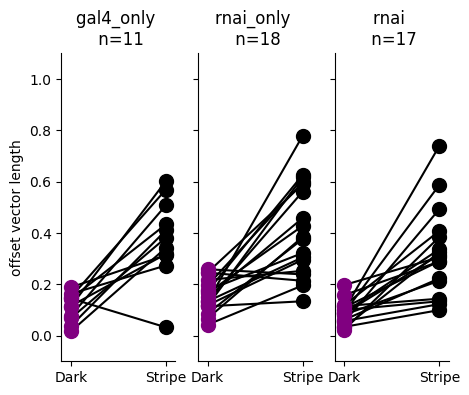

In [10]:
fig,ax = plt.subplots(1,3,sharey=True, figsize=[5,4])

gal4_only_df = stats_df_plot.loc[stats_df_plot['condition']=='gal4_only']
ax[0].set_title(f'gal4_only \n n={gal4_only_df.shape[0]}')

ax[0].plot([0,1], gal4_only_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[0].scatter(np.zeros((gal4_only_df.shape[0],)), gal4_only_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[0].scatter(np.ones((gal4_only_df.shape[0],)), gal4_only_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)

rnai_only_df = stats_df_plot.loc[stats_df_plot['condition']=='rnai_only']
ax[1].set_title(f'rnai_only \n n={rnai_only_df.shape[0]}')

ax[1].plot([0,1], rnai_only_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[1].scatter(np.zeros((rnai_only_df.shape[0],)), rnai_only_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[1].scatter(np.ones((rnai_only_df.shape[0],)), rnai_only_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)

rnai_df = stats_df_plot.loc[stats_df_plot['condition']=='rnai']
ax[2].set_title(f'rnai \n n={rnai_df.shape[0]}')

ax[2].plot([0,1], rnai_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[2].scatter(np.zeros((rnai_df.shape[0],)), rnai_df['offset_mag_dark'], color='purple', alpha=1, s=100)
ax[2].scatter(np.ones((rnai_df.shape[0],)), rnai_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)


for _ax in ax:
    _ax.set_ylim([-0.1,1.1])
    _ax.set_xlim([-.1,1.1])
    _ax.set_yticks([0,.2,.4,.6,.8,1.])

    _ax.set_xticks([0, 1], labels=['Dark', 'Stripe'])
    _ax.spines['top'].set_visible(False)
    _ax.spines['right'].set_visible(False)
    
ax[0].set_ylabel('offset vector length')
# fig.suptitle('OctAlpha2R RNAi')
print(gal4_only_df.shape[0], rnai_only_df.shape[0], rnai_df.shape[0])

# fig.savefig(figfolder / 'offset_mag_summary.pdf', format='pdf')


In [10]:
import pingouin as pg
from pingouin import mixed_anova, pairwise_tests
aov = mixed_anova(dv='offset_var_logit', between='condition',
                  within='dark', subject='fly_id', data=stats_df_unique)
aov

,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,6.469268,2,42,3.234634,5.508467,7.508072e-03,0.207800,NaN
1,dark,54.231843,1,42,54.231843,94.940535,2.421400e-12,0.693298,1.0
2,Interaction,0.150000,2,42,0.075000,0.131298,8.773147e-01,0.006213,NaN


In [11]:
tt = pairwise_tests(dv='offset_var_logit', between='condition',
                   subject='fly_id', within='dark', data=stats_df_unique,
                   padjust='holm', parametric=True, interaction=True, within_first=False)

print(tt['Contrast'].unique())
tt

['condition' 'dark' 'condition * dark']


,Contrast,condition,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,condition,-,gal4_only,rnai,False,True,-0.945883,20.294169,two-sided,3.553352e-01,0.355335,holm,0.5,-0.361376
1,condition,-,gal4_only,rnai_only,False,True,1.842932,18.530990,two-sided,8.139559e-02,0.162791,holm,1.219,0.722048
2,condition,-,rnai,rnai_only,False,True,3.396043,32.000000,two-sided,1.842264e-03,0.005527,holm,18.933,1.137317
3,dark,-,0,1,True,True,-9.942008,44.000000,two-sided,7.991343e-13,NaN,NaN,1.033e+10,-1.942189
4,condition * dark,gal4_only,0,1,True,True,-3.902410,10.000000,two-sided,2.949433e-03,0.002949,holm,16.424,-1.717854
5,condition * dark,rnai,0,1,True,True,-6.681660,16.000000,two-sided,5.271562e-06,0.000016,holm,3939.506,-2.109865
6,condition * dark,rnai_only,0,1,True,True,-6.621149,16.000000,two-sided,5.878522e-06,0.000016,holm,3570.736,-2.117410


In [12]:
tt = pairwise_tests(dv='offset_var_logit', between='condition',
                   subject='fly_id', within='dark', data=stats_df_unique,
                   padjust='holm', parametric=False, interaction=True, within_first=True, correction=False)

print(tt['Contrast'].unique())
tt

['dark' 'condition' 'dark * condition']


,Contrast,dark,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,dark,-,0,1,True,False,NaN,27.0,two-sided,7.167955e-11,NaN,NaN,-1.942189
1,condition,-,gal4_only,rnai,False,False,69.0,NaN,two-sided,2.589109e-01,0.258911,holm,-0.361376
2,condition,-,gal4_only,rnai_only,False,False,129.0,NaN,two-sided,9.967870e-02,0.199357,holm,0.722048
3,condition,-,rnai,rnai_only,False,False,235.0,NaN,two-sided,1.935743e-03,0.005807,holm,1.137317
4,dark * condition,0,gal4_only,rnai,False,False,64.0,NaN,two-sided,1.725137e-01,0.517541,holm,-0.241761
5,dark * condition,0,gal4_only,rnai_only,False,False,100.0,NaN,two-sided,7.777577e-01,0.777758,holm,0.339920
6,dark * condition,0,rnai,rnai_only,False,False,195.0,NaN,two-sided,8.503753e-02,0.369256,holm,0.645147
7,dark * condition,1,gal4_only,rnai,False,False,68.0,NaN,two-sided,2.395911e-01,0.517541,holm,-0.274097
8,dark * condition,1,gal4_only,rnai_only,False,False,132.0,NaN,two-sided,7.385115e-02,0.369256,holm,0.722037
9,dark * condition,1,rnai,rnai_only,False,False,236.0,NaN,two-sided,1.722286e-03,0.010334,holm,1.140583
